# VoltRelay Energy: Why Is Growth Not Turning Into Profit?
Operations, Customer Retention & Margin Investigation | Jan 2024 - Jun 2025 | 6 Indian cities | ~3.9M swap attempts

---

## 1. Problem Statement
VoltRelay's swaps and revenue are growing, but service failures are rising faster, new riders are leaving, and profit per swap is shrinking. Leadership does not know why, or where to spend the next budget.

## 2. What This Notebook Answers (one line each)
| # | Business question | Where answered |
|---|---|---|
| 1 | Is growth real, and when did profit per swap stop following it? | S4 Network performance |
| 2 | Where and when do swaps fail or queue, and is it spread evenly or concentrated? | S5 Service quality |
| 3 | Which stations underperform despite high demand, and do expansion waves help? | S6 Stations and geography |
| 4 | Do battery suppliers, lots or health levels explain poor range or failures? | S7 Battery and equipment |
| 5 | Did pricing changes and fleet partner contracts help or hurt margin? | S8 Pricing and partners |
| 6 | Why do new riders stop coming back, and which factors are primary vs secondary? | S9 Retention and churn |
| 7 | Do support tickets add information beyond their categories? | S10 Support tickets |
| 8 | What explains the margin drop, and which of the 4 investments does the evidence support? | S11 Root cause and investment |

## 3. The 4 Investment Options Being Judged
1. More stations 2. More batteries 3. Network-wide pricing rollout 4. Exclusive long-term fleet deal

## 4. Method in 5 Steps
1. **Check the data first (S1-S2):** keys, joins and known defects (firmware timestamp bug, duplicates, test stations, city spellings, sensor outliers, missing telemetry, biased CSAT). Each fix is logged in `CLEAN_LOG`.
2. **Use the right grain (S3):** attempts, riders, tickets and station-hours are kept separate. Joins are many-to-one only, so nothing is double-counted.
3. **Separate volume from unit economics (S3-S4):** margin is built in layers: CM1 = revenue - energy, CM2 = CM1 - rent and maintenance, CM3 = CM2 - battery wear.
4. **Narrow from symptom to cause (S4-S9):** trend, then segment, then station, then equipment, then price, then rider behaviour.
5. **Be honest about causation (S8-S9):** this is observational data, so results are associations. Pricing uses difference-in-differences, and churn uses cohorts plus regression.

## 5. Key Definitions
- **Completed swap:** `event_type == swap_completed`. **Attempt:** any row.
- **Service failure:** no charged battery + system error + abandoned queue (rider cancellations are reported separately).
- **Revenue:** net amount charged on completed swaps only.
- **Stockout:** known hour with zero charged packs. Missing telemetry is unknown, never zero.
- **New-rider retention:** completed swap in days 14-43 after signup, among riders activated in days 0-13.

## 6. Assumptions and Limits
- Only costs present in the data are used (energy, rent, maintenance, battery wear). Staff, marketing and HQ costs are excluded.
- Battery wear assumes end-of-life at 80% state of health (`EOL_SOH`, editable).
- Results show association, not proof of cause.

## 7. How to Run
Python 3.10+, with pandas, numpy, matplotlib, seaborn, scipy, statsmodels. Set `DATA_DIR` in S0 to the folder holding the 8 files, then run top to bottom. The raw data is never overwritten: every fix is a new column or a flag.

## 8. Headline Results (fill in after running; use values from the `EV` dictionary)
- Swaps grew [X]x while CM2 per swap changed [±X%] (diverged in [month]).
- Service failure rate: [X%] to [Y%]; worst 10% of stations = [X%] of failures.
- Churn is most associated with [factor]; largest partner ranks #[X] by revenue vs #[Y] by margin.
- Recommended investment order: [1 ... 4].

In [33]:
import os, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 80); pd.set_option("display.width", 220)

DATA_DIR = "C:/Mrinalini Tripathi"
EV = {}          # evidence dictionary, filled as we go
CLEAN_LOG = []   # cleaning decisions
def path(n):
    for ext in (".csv.gz", ".csv"):
        f = os.path.join(DATA_DIR, n + ext)
        if os.path.exists(f): return f
    raise FileNotFoundError(n)

sw_cat = ["rider_id","station_id","event_type","battery_in_id","battery_out_id",
          "tariff_code","payment_mode","station_firmware","sync_mode"]
sw_f32 = ["queue_wait_sec","soc_in_pct","soh_in_pct","soc_out_pct","soh_out_pct","km_since_last_swap",
          "list_price_inr","discount_inr","amount_charged_inr","energy_to_recharge_kwh"]
dt = {c: "category" for c in sw_cat} | {c: "float32" for c in sw_f32}
S = pd.read_csv(path("swap_events"), dtype=dt)
S["event_ts"] = pd.to_datetime(S["event_ts"], errors="coerce")

riders = pd.read_csv(path("riders"), parse_dates=["signup_date"])
bat    = pd.read_csv(path("batteries"), parse_dates=["manufacture_date","commission_date","retired_date"])
tk     = pd.read_csv(path("support_tickets"), parse_dates=["created_ts"])
st     = pd.read_csv(path("stations"), parse_dates=["commissioned_date","decommissioned_date",
                     "firmware_updated_date","competitor_within_1_5km_since"])
cdc    = pd.read_csv(path("city_daily_context"), parse_dates=["date"])
fp     = pd.read_csv(path("fleet_partners"), parse_dates=["contract_start_date","amendment_date"])
hr     = pd.read_csv(path("station_hourly_status"), parse_dates=["hour_start"])
tables = dict(swap_events=S, station_hourly_status=hr, riders=riders, batteries=bat,
              support_tickets=tk, stations=st, city_daily_context=cdc, fleet_partners=fp)

# Data understanding

In [34]:
doc_rows = dict(swap_events=3877013, station_hourly_status=1487712, riders=20000, batteries=6500,
                support_tickets=44000, stations=152, city_daily_context=3282, fleet_partners=12)
inv = pd.DataFrame([{"table": n, "rows": len(d), "documented_rows": doc_rows[n], "cols": d.shape[1],
        "mem_MB": round(d.memory_usage(deep=True).sum()/1e6, 1),
        "null_%": round(d.isna().sum().sum()/d.size*100, 2)} for n, d in tables.items()])
display(inv)

# Primary keys
pk = {"swap_events":["event_id"], "station_hourly_status":["station_id","hour_start"], "riders":["rider_id"],
      "batteries":["battery_id"], "support_tickets":["ticket_id"], "stations":["station_id"],
      "city_daily_context":["city","date"], "fleet_partners":["partner_id"]}
for n, k in pk.items():
    d = tables[n]; print(f"PK {n:24s} {k}  duplicated keys = {d.duplicated(k).sum()}")

# Foreign keys: orphan rate and parent uniqueness (join safety)
def fk(child, col, parent_ids, label):
    c = child[col].dropna(); orphan = ~c.isin(parent_ids)
    return {"fk": label, "non_null": len(c), "orphans": int(orphan.sum()), "orphan_%": round(orphan.mean()*100, 4)}
fks = [fk(S,"rider_id",riders.rider_id,"swap.rider_id->riders"),
       fk(S,"station_id",st.station_id,"swap.station_id->stations"),
       fk(S,"battery_in_id",bat.battery_id,"swap.battery_in->batteries"),
       fk(S,"battery_out_id",bat.battery_id,"swap.battery_out->batteries"),
       fk(hr,"station_id",st.station_id,"hourly.station_id->stations"),
       fk(riders,"partner_id",fp.partner_id,"riders.partner_id->partners"),
       fk(tk,"rider_id",riders.rider_id,"tickets.rider_id->riders"),
       fk(tk,"station_id",st.station_id,"tickets.station_id->stations"),
       fk(tk,"battery_id",bat.battery_id,"tickets.battery_id->batteries")]
display(pd.DataFrame(fks))

print("\nevent_type mix:"); display(S.event_type.value_counts(normalize=True).round(4).to_frame("share"))
print("Null pattern by event_type (share null):")
display(S.groupby("event_type", observed=True)[["battery_in_id","battery_out_id","soh_out_pct","km_since_last_swap",
        "energy_to_recharge_kwh","amount_charged_inr"]].apply(lambda g: g.isna().mean()).round(3))
print("Unparseable timestamps:", S.event_ts.isna().sum(), "| range:", S.event_ts.min(), "->", S.event_ts.max())
print("event_id unique:", S.event_id.is_unique)

,table,rows,documented_rows,cols,mem_MB,null_%
0,swap_events,3877013,3877013,22,507.1,1.22
1,station_hourly_status,1487712,1487712,14,308.2,4.31
2,riders,20000,20000,12,11.3,5.35
3,batteries,6500,6500,13,2.5,11.98
4,support_tickets,44000,44000,12,25.2,9.55
5,stations,152,152,22,0.1,8.76
6,city_daily_context,3282,3282,12,0.4,8.05
7,fleet_partners,12,12,12,0.0,15.28


PK swap_events              ['event_id']  duplicated keys = 0
PK station_hourly_status    ['station_id', 'hour_start']  duplicated keys = 0
PK riders                   ['rider_id']  duplicated keys = 0
PK batteries                ['battery_id']  duplicated keys = 0
PK support_tickets          ['ticket_id']  duplicated keys = 0
PK stations                 ['station_id']  duplicated keys = 0
PK city_daily_context       ['city', 'date']  duplicated keys = 0
PK fleet_partners           ['partner_id']  duplicated keys = 0


,fk,non_null,orphans,orphan_%
0,swap.rider_id->riders,3877013,0,0.0
1,swap.station_id->stations,3877013,0,0.0
2,swap.battery_in->batteries,3848731,0,0.0
3,swap.battery_out->batteries,3645809,0,0.0
4,hourly.station_id->stations,1487712,0,0.0
5,riders.partner_id->partners,12372,0,0.0
6,tickets.rider_id->riders,44000,0,0.0
7,tickets.station_id->stations,41773,0,0.0
8,tickets.battery_id->batteries,30765,0,0.0



event_type mix:


,share
event_type,
swap_completed,0.9404
failed_no_charged_battery,0.0347
abandoned_queue,0.0177
cancelled_by_rider,0.0043
failed_system_error,0.0030


Null pattern by event_type (share null):


,battery_in_id,battery_out_id,soh_out_pct,km_since_last_swap,energy_to_recharge_kwh,amount_charged_inr
event_type,,,,,,
abandoned_queue,0.0,1.0,1.0,0.0,1.0,0.0
cancelled_by_rider,1.0,1.0,1.0,1.0,1.0,0.0
failed_no_charged_battery,0.0,1.0,1.0,0.0,1.0,0.0
failed_system_error,1.0,1.0,1.0,1.0,1.0,0.0
swap_completed,0.0,0.0,0.0,0.0,0.0,0.0


Unparseable timestamps: 0 | range: 2024-01-01 00:00:33 -> 2025-06-30 23:59:23
event_id unique: True


# Data quality and cleaning (each issue: size, rule, preserved raw, downstream effect)

Unparseable event_ts: 0 | range: 2024-01-01 00:00:33 -> 2025-06-30 23:59:23


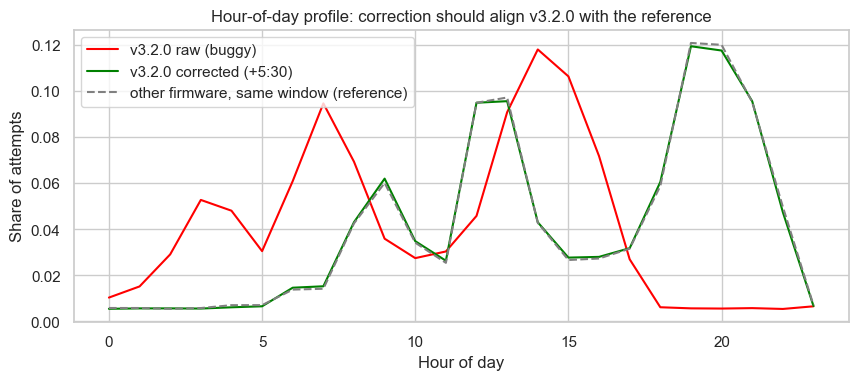

Test stations: ['STN-TST-01', 'STN-TST-02'] | rows: 62031 | revenue on them: 3930760.0


,offline_batch,realtime (baseline)
window_sec,,
30,0,0
60,0,0
120,0,0
180,0,0
300,0,0


Duplicates flagged: 0
Analysis set A: 3,814,982 of 3,877,013 rows
Raw rider city spellings: ['BLR', 'Bangalore', 'Bengaluru', 'Bombay', 'Delhi', 'Delhi NCR', 'Gurgaon', 'HYD', 'Hyd', 'Hyderabad', 'JAI', 'Jaipur', 'MUM', 'Mumbai', 'New Delhi', 'PUN', 'Pune', 'bengaluru ', 'hyderabad', 'jaipur', 'pune']


home_city,Bengaluru,Delhi NCR,Hyderabad,Jaipur,Mumbai,Pune
home_city_raw,,,,,,
BLR,53,0,0,0,0,0
Bangalore,32,0,0,0,0,0
Bengaluru,4175,0,0,0,0,0
Bombay,0,0,0,0,53,0
Delhi,0,25,0,0,0,0
Delhi NCR,0,3783,0,0,0,0
Gurgaon,0,36,0,0,0,0
HYD,0,0,31,0,0,0
Hyd,0,0,31,0,0,0


Cities after standardising: {'Bengaluru': 4310, 'Delhi NCR': 3886, 'Hyderabad': 3485, 'Pune': 2929, 'Mumbai': 2874, 'Jaipur': 2516}
Rider home_city nulls: 0 | stations.city nulls: 0 | context city nulls: 0
soc_in_pct: >100 in 0 rows (0.00% of non-null), max 28.4
soh_in_pct: >100 in 3,298 rows (0.09% of non-null), max 101.4
soc_out_pct: >100 in 3,634 rows (0.10% of non-null), max 103.0
soh_out_pct: >100 in 2,752 rows (0.08% of non-null), max 101.3
km invalid (<=0 or >3x class median): 15287 (0.40% of non-null)
{'ok': 0.968, 'partial': 0.025, 'missing': 0.006}
telemetry_status  missing     ok  partial
station_id                               
fair                 0.00  0.961    0.039
good                 0.00  0.990    0.010
poor                 0.04  0.891    0.069


,n,response_rate,csat
res_q,,,
0.0,9525,0.435801,3.540834
1.0,9557,0.442712,3.540534
2.0,9428,0.434875,3.562927
3.0,9378,0.282256,3.615036


CSAT naive mean 3.560 | response-weighted 3.565 | overall response 34.4%
Ticket categories: {'no_battery_available': 11647, 'other': 9484, 'low_range': 6636, 'app_issue': 5787, 'long_queue': 5731, 'billing_dispute': 4715}
Tickets with comment: 1.0 | generic category share: 0.347
Generic-category tickets mentioning battery/range words: 3057 (20.0% of generic)
Top tokens in generic tickets (use to tune LEX):
{'lag': 6210, 'raha': 6210, 'hai': 6210, 'app': 3847, 'general': 3274, 'issue': 3274, 'with': 3274, 'the': 3274, 'vehicle': 3274, 'performance': 3274, 'bike': 3153, 'problem': 3153, 'overall': 3153, 'scooter': 3057, 'weak': 3057, 'aajkal': 3057, 'unable': 1940, 'to': 1940, 'scan': 1940, 'qr': 1940, 'code': 1940, 'at': 1940, 'crash': 1935, 'ho': 1935, 'gaya': 1935, 'swap': 1935, 'ke': 1935, 'time': 1935, 'not': 1912, 'showing': 1912, 'nearby': 1912, 'station': 1536, 'stations': 1534, 'staion': 404, 'staions': 378}


kw_battery_range,no_battery_kw,battery_kw
category,,
app_issue,5787,0
billing_dispute,4715,0
long_queue,5731,0
low_range,2115,4521
no_battery_available,11647,0
other,6427,3057


,issue,impact,treatment,downstream
0,Unparseable event_ts,0 rows,Excluded from time analysis,Negligible if tiny
1,Firmware v3.2.0 timestamp shift,"139,490 rows (3.60%)","Add 5h30 to event_ts, keep event_ts_raw","Hour-of-day, daily and month-edge counts corre..."
2,STN-TST test stations,62031 rows,Flag and exclude from network analysis,Prevents zero-value rows distorting rates
3,Offline-batch near-duplicates,0 rows,Drop later row if same rider/station/type/batt...,"Avoids double-counting swaps, revenue, energy;..."
4,Inconsistent home_city,21 spellings -> 6 cities,Substring-rule mapping + fuzzy fallback; raw k...,Rider geography only; swap geography uses stat...
5,Charge readings >100%,see printout,"Clip to 100 in *_clean (calibration drift, sma...",Raw preserved; averages barely move
6,Negative/implausible km,"15,287 rows","Set to NaN in km_clean (not zero, not imputed)",Range analysis uses valid readings only; cover...
7,Missing hourly telemetry,0.6% hours without stock reading,Stockout = NaN when unknown; rates use known h...,Avoids understating stockouts at poor-connecti...
8,CSAT missing not at random,66% missing,Report response rate; reweight by resolution-t...,"CSAT used descriptively only, not as a churn d..."
9,Ticket category inaccuracy,"3,057 generic tickets with battery wording",Add kw_* flags; keep original category,Battery-related complaint volume reported as r...


In [35]:
# ============ S2. DATA QUALITY & CLEANING (idempotent: safe to rerun) ============
# ---- Parameters (change here only) ----
FW_VERSION, FW_START, FW_END = "v3.2.0", "2025-03-10", "2025-04-15"   # END exclusive (covers Apr 14)
FW_SHIFT      = pd.Timedelta(hours=5, minutes=30)
TEST_PREFIX   = "STN-TST"
DUP_WINDOW    = 180
DUP_GRID      = (30, 60, 120, 180, 300)
KM_CAP_MULT   = 3
GENERIC_CATS  = ["other", "app_issue"]
CANON_CITIES  = ["Bengaluru", "Delhi NCR", "Hyderabad", "Pune", "Mumbai", "Jaipur"]
CITY_RULES = [                            # substring tokens on lowercase letters-only string -> city
    (("ban", "ben", "blr", "bgl"),                         "Bengaluru"),
    (("del", "ncr", "ggn", "gur", "noi", "fari"),          "Delhi NCR"),
    (("hyd", "sec", "hyb"),                                "Hyderabad"),
    (("pun", "pnq"),                                       "Pune"),
    (("mum", "bom", "navi", "thane"),                      "Mumbai"),
    (("jai", "jpr"),                                       "Jaipur"),
]

CLEAN_LOG.clear()                          # avoid duplicate log rows on rerun
def log(issue, impact, rule, effect):
    CLEAN_LOG.append(dict(issue=issue, impact=impact, treatment=rule, downstream=effect))

# ---- Reset step: undo any earlier run of this cell ----
if "event_ts_raw" in S.columns:
    S["event_ts"] = S["event_ts_raw"]      # restore un-shifted timestamps
for d_, raw_c, new_c in [(riders, "home_city_raw", "home_city"), (st, "city_raw", "city"), (cdc, "city_raw", "city")]:
    if raw_c in d_.columns:
        d_[new_c] = d_[raw_c]              # restore original spellings
for c_ in ["city", "slots_3w", "stockout"]:
    if c_ in hr.columns: hr.drop(columns=c_, inplace=True)

# 2.0 Unparseable timestamps + range sanity
bad_ts = S.event_ts.isna()
print("Unparseable event_ts:", int(bad_ts.sum()), "| range:", S.event_ts.min(), "->", S.event_ts.max())
log("Unparseable event_ts", f"{int(bad_ts.sum())} rows", "Excluded from time analysis", "Negligible if tiny")

# 2.1 Firmware v3.2.0 timestamp bug (+5h30). Window is defined on RECORDED timestamps.
S["event_ts_raw"] = S["event_ts"]
fw_is  = S.station_firmware.astype(str).eq(FW_VERSION)
in_win = (S.event_ts_raw >= FW_START) & (S.event_ts_raw < FW_END)
win = in_win & fw_is
ref = in_win & ~fw_is
S["ts_fixed_flag"] = win
S.loc[win, "event_ts"] = S.loc[win, "event_ts_raw"] + FW_SHIFT
hp = lambda m, col: S.loc[m, col].dt.hour.value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(hp(win, "event_ts_raw"), label=f"{FW_VERSION} raw (buggy)", color="red")
ax.plot(hp(win, "event_ts"),     label=f"{FW_VERSION} corrected (+5:30)", color="green")
ax.plot(hp(ref, "event_ts_raw"), label="other firmware, same window (reference)", color="grey", ls="--")
ax.set(title="Hour-of-day profile: correction should align v3.2.0 with the reference",
       xlabel="Hour of day", ylabel="Share of attempts")
ax.legend(); plt.show()
log("Firmware v3.2.0 timestamp shift", f"{int(win.sum()):,} rows ({win.mean()*100:.2f}%)",
    "Add 5h30 to event_ts, keep event_ts_raw", "Hour-of-day, daily and month-edge counts corrected")

# 2.2 Test stations
test_ids = [c for c in S.station_id.cat.categories if str(c).startswith(TEST_PREFIX)]
is_test = S.station_id.isin(test_ids)
print("Test stations:", test_ids, "| rows:", int(is_test.sum()),
      "| revenue on them:", float(S.loc[is_test, "amount_charged_inr"].sum()))
log("STN-TST test stations", f"{int(is_test.sum())} rows", "Flag and exclude from network analysis",
    "Prevents zero-value rows distorting rates")

# 2.3 Near-duplicates (offline_batch only)
keys = ["rider_id", "station_id", "event_type", "battery_in_id", "battery_out_id"]
def dup_flags(mask, window):
    sub = S.loc[mask, keys + ["event_ts"]]
    K = pd.DataFrame({k: sub[k].cat.codes for k in keys}, index=sub.index)
    K["ts"] = sub.event_ts
    K = K.sort_values(keys + ["ts"])
    same = (K[keys] == K[keys].shift()).all(axis=1)
    gap = K.ts.diff().dt.total_seconds()
    return (same & (gap <= window)).reindex(sub.index)
off = S.sync_mode.astype(str).eq("offline_batch"); rt = ~off
sens = pd.DataFrame({w: {"offline_batch": int(dup_flags(off, w).sum()),
                         "realtime (baseline)": int(dup_flags(rt, w).sum())} for w in DUP_GRID}).T
display(sens.rename_axis("window_sec"))
S["is_dup"] = False
S.loc[off, "is_dup"] = dup_flags(off, DUP_WINDOW).values
print("Duplicates flagged:", int(S.is_dup.sum()))
log("Offline-batch near-duplicates", f"{int(S.is_dup.sum()):,} rows",
    f"Drop later row if same rider/station/type/batteries within {DUP_WINDOW}s and sync_mode=offline_batch",
    "Avoids double-counting swaps, revenue, energy; realtime rows never dropped")

# 2.4 Master clean filter
S["keep"] = ~(bad_ts | is_test | S.is_dup)
A = S[S.keep].reset_index(drop=True)
print(f"Analysis set A: {len(A):,} of {len(S):,} rows")

# 2.5 City standardisation (substring rules, fuzzy fallback, audit, no hard crash)
import difflib
UNMAPPED = set()
def canon_city(x):
    if pd.isna(x): return np.nan
    s = re.sub(r"[^a-z]", "", str(x).lower())
    for toks, name in CITY_RULES:
        if any(t in s for t in toks): return name
    m = difflib.get_close_matches(s, [c.lower().replace(" ", "") for c in CANON_CITIES], n=1, cutoff=0.6)
    if m: return next(c for c in CANON_CITIES if c.lower().replace(" ", "") == m[0])
    UNMAPPED.add(str(x)); return np.nan

for d_, raw_c, new_c in [(riders, "home_city_raw", "home_city"), (st, "city_raw", "city"), (cdc, "city_raw", "city")]:
    if raw_c not in d_.columns: d_[raw_c] = d_[new_c]
    d_[new_c] = d_[raw_c].map(canon_city)

print("Raw rider city spellings:", sorted(riders.home_city_raw.dropna().unique()))
display(pd.crosstab(riders.home_city_raw, riders.home_city.fillna("UNMAPPED/NULL")))   # audit table
if UNMAPPED: print("WARNING - unmapped values left as NaN, extend CITY_RULES:", sorted(UNMAPPED))
print("Cities after standardising:", riders.home_city.value_counts().to_dict())
print("Rider home_city nulls:", int(riders.home_city.isna().sum()),
      "| stations.city nulls:", int(st.city.isna().sum()), "| context city nulls:", int(cdc.city.isna().sum()))
log("Inconsistent home_city", f"{riders.home_city_raw.nunique()} spellings -> {riders.home_city.nunique()} cities",
    "Substring-rule mapping + fuzzy fallback; raw kept in home_city_raw", "Rider geography only; swap geography uses station city")

# 2.6 Charge readings >100 and distance outliers: raw kept, *_clean created
for c in ["soc_in_pct", "soh_in_pct", "soc_out_pct", "soh_out_pct"]:
    n = int((A[c] > 100).sum()); A[c + "_clean"] = A[c].clip(upper=100)
    print(f"{c}: >100 in {n:,} rows ({n/max(A[c].notna().sum(),1)*100:.2f}% of non-null), max {A[c].max():.1f}")
log("Charge readings >100%", "see printout", "Clip to 100 in *_clean (calibration drift, small magnitude)",
    "Raw preserved; averages barely move")

def lk(m, key):   # fast categorical-key lookup, NaN-safe (used by S3+)
    cats = key.cat.categories; codes = key.cat.codes.to_numpy()
    arr = m.reindex(cats).to_numpy(); out = arr[codes]
    if arr.dtype.kind in "fc": return np.where(codes < 0, np.nan, out)
    if arr.dtype.kind == "M": return np.where(codes < 0, np.datetime64("NaT"), out)
    return np.where(codes < 0, None, out)

rv = riders.set_index("rider_id").vehicle_class
A["vehicle_class"] = pd.Categorical(lk(rv, A.rider_id))
pos = A.km_since_last_swap.where(A.km_since_last_swap > 0)
cap = pos.groupby(A.vehicle_class, observed=True).transform("median") * KM_CAP_MULT
bad_km = A.km_since_last_swap.notna() & ((A.km_since_last_swap <= 0) | (A.km_since_last_swap > cap))
print("km invalid (<=0 or >%dx class median):" % KM_CAP_MULT, int(bad_km.sum()),
      f"({bad_km.sum()/A.km_since_last_swap.notna().sum()*100:.2f}% of non-null)")
A["km_clean"] = A.km_since_last_swap.mask(bad_km)
log("Negative/implausible km", f"{int(bad_km.sum()):,} rows", "Set to NaN in km_clean (not zero, not imputed)",
    "Range analysis uses valid readings only; coverage reported")

# 2.7 Hourly telemetry: unknown != zero stock
hr = hr[~hr.station_id.astype(str).str.startswith(TEST_PREFIX)].copy()
print(hr.telemetry_status.value_counts(normalize=True).round(3).to_dict())
print(pd.crosstab(hr.station_id.map(st.set_index("station_id").connectivity_tier),
                  hr.telemetry_status, normalize="index").round(3))
hr = hr.merge(st[["station_id", "city", "slots_3w"]], on="station_id", how="left")
known = hr.charged_2w_min.notna()
s_any = hr.charged_2w_min.eq(0) | ((hr.slots_3w > 0) & hr.charged_3w_min.eq(0))
hr["stockout"] = np.where(known, s_any.astype(float), np.nan)      # NaN = unknown, never 0
log("Missing hourly telemetry", f"{(~known).mean()*100:.1f}% hours without stock reading",
    "Stockout = NaN when unknown; rates use known hours only", "Avoids understating stockouts at poor-connectivity stations")

# 2.8 CSAT selection bias
tk["has_csat"] = tk.csat_score.notna()
tk["res_q"] = pd.qcut(tk.resolution_hours, 4, labels=False, duplicates="drop")
rr = tk.groupby("res_q").agg(n=("ticket_id", "size"), response_rate=("has_csat", "mean"), csat=("csat_score", "mean"))
display(rr)
sc = tk[tk.has_csat & tk.res_q.notna()]
w = 1 / sc.res_q.map(rr.response_rate.to_dict())
print(f"CSAT naive mean {sc.csat_score.mean():.3f} | response-weighted {np.average(sc.csat_score, weights=w):.3f} "
      f"| overall response {tk.has_csat.mean()*100:.1f}%")
log("CSAT missing not at random", f"{(1-tk.has_csat.mean())*100:.0f}% missing",
    "Report response rate; reweight by resolution-time quartile; never impute", "CSAT used descriptively only, not as a churn driver")

# 2.9 Ticket categories vs comments (Hinglish lexicon)
print("Ticket categories:", tk.category.value_counts(dropna=False).to_dict())     # confirm GENERIC_CATS
LEX = {"battery_range": r"range|km\b|jaldi|drain|utar|khatam|charge nahi|weak|kharab|low battery|soh|health|dead",
       "no_stock": r"no battery|battery nahi|khali|empty|stock|not available|charged battery",
       "queue": r"wait|line|queue|intezaar|der\b|lamba",
       "payment": r"refund|paisa|paise|deduct|twice|upi|wallet|bill|invoice|charge hua",
       "app": r"\bapp\b|login|otp|crash|hang|update",
       "vehicle": r"scooter|bike|vehicle|motor|controller|gaadi"}
txt = tk.rider_comment.fillna("").str.lower()
tk["has_comment"] = txt.str.len() > 0
for k, pat in LEX.items():
    tk["kw_" + k] = txt.str.contains(pat, regex=True)
gen = tk.category.isin(GENERIC_CATS)
print("Tickets with comment:", round(tk.has_comment.mean(), 3), "| generic category share:", round(gen.mean(), 3))
print("Generic-category tickets mentioning battery/range words:", int((gen & tk.kw_battery_range).sum()),
      f"({(gen & tk.kw_battery_range).sum()/max(gen.sum(),1)*100:.1f}% of generic)")
print("Top tokens in generic tickets (use to tune LEX):")
print(pd.Series(" ".join(txt[gen]).split()).value_counts().head(40).to_dict())
display(pd.crosstab(tk.category, tk.kw_battery_range).rename(columns={False: "no_battery_kw", True: "battery_kw"}))
log("Ticket category inaccuracy", f"{int((gen & tk.kw_battery_range).sum()):,} generic tickets with battery wording",
    "Add kw_* flags; keep original category", "Battery-related complaint volume reported as range (original vs text-adjusted)")
display(pd.DataFrame(CLEAN_LOG))

# Data model, derived fields and KPI definitions

In [36]:
# Grain: swap_events = attempt (fact). hourly = station-hour (fact). tickets = ticket (fact).
# Dims: riders, stations, batteries, fleet_partners, city_daily_context.
# Joins are all many-to-one, verified by unique parent keys. battery_in and battery_out are mapped separately
# (never one join twice), tickets are aggregated before being joined to riders to avoid fan-out.
for n, k in [("riders","rider_id"),("stations","station_id"),("batteries","battery_id"),("fleet_partners","partner_id")]:
    assert tables[n][k].is_unique, n
stx = st.set_index("station_id"); rx = riders.set_index("rider_id"); bx = bat.set_index("battery_id")
A["city"]      = pd.Categorical(lk(stx.city, A.station_id))
A["charger_gen"] = pd.Categorical(lk(stx.charger_generation, A.station_id))
A["loc_type"]  = pd.Categorical(lk(stx.location_type, A.station_id))
A["wave"]      = pd.Categorical(lk(stx.expansion_wave, A.station_id))
A["conn"]      = pd.Categorical(lk(stx.connectivity_tier, A.station_id))
A["grid_tariff"] = lk(stx.grid_tariff_inr_kwh, A.station_id)
A["partner"]   = pd.Categorical(lk(rx.partner_id, A.rider_id))
A["plan"]      = pd.Categorical(lk(rx.plan_type, A.rider_id))
A["supplier_in"] = pd.Categorical(lk(bx.supplier, A.battery_in_id))
A["lot_in"]    = pd.Categorical(lk(bx.manufacturing_lot, A.battery_in_id))
A["ts"] = A.event_ts
A["date"]  = A.ts.dt.normalize(); A["month"] = A.ts.dt.to_period("M").dt.to_timestamp()
A["hour"]  = A.ts.dt.hour.astype("int8")
et = A.event_type.astype(str)
A["completed"] = et.eq("swap_completed")
A["f_stock"] = et.eq("failed_no_charged_battery"); A["f_sys"] = et.eq("failed_system_error")
A["f_aband"] = et.eq("abandoned_queue"); A["f_cancel"] = et.eq("cancelled_by_rider")
A["svc_fail"] = A.f_stock | A.f_sys | A.f_aband            # service failure (rider-cancel reported separately)

# Money exists only for completed swaps (failed rows with amount>0 are checked, not summed)
print("Failed rows with amount>0:", int(((~A.completed) & (A.amount_charged_inr > 0)).sum()),
      "| completed with null amount:", int((A.completed & A.amount_charged_inr.isna()).sum()),
      "| completed with null energy:", int((A.completed & A.energy_to_recharge_kwh.isna()).sum()))
A["rev"]    = A.amount_charged_inr.where(A.completed)
A["list_c"] = A.list_price_inr.where(A.completed); A["disc_c"] = A.discount_inr.where(A.completed)
A["energy_cost"] = (A.energy_to_recharge_kwh * A.grid_tariff).where(A.completed)

# Fixed cost (rent + maintenance, real data), allocated pro-rata by active days, then per completed swap at station-month
months = pd.DataFrame({"month": pd.date_range("2024-01-01", "2025-06-01", freq="MS")})
g = st[~st.station_id.str.startswith("STN-TST")][["station_id","city","monthly_rent_inr","monthly_maintenance_inr",
      "commissioned_date","decommissioned_date"]].merge(months, how="cross")
s0 = g[["month","commissioned_date"]].max(axis=1)
s1 = pd.concat([g.month + pd.offsets.MonthEnd(0), g.decommissioned_date.fillna(pd.Timestamp("2025-06-30"))], axis=1).min(axis=1)
g["active_days"] = ((s1 - s0).dt.days + 1).clip(lower=0)
g["fixed_cost"] = (g.monthly_rent_inr + g.monthly_maintenance_inr) * g.active_days / g.month.dt.days_in_month
sm = A[A.completed].groupby(["station_id","month"], observed=True).size().rename("n_done").reset_index()
sm = g.merge(sm, on=["station_id","month"], how="left").fillna({"n_done": 0})
sm["fixed_per_swap"] = sm.fixed_cost / sm.n_done.replace(0, np.nan)
sm["station_id"] = pd.Categorical(sm.station_id, categories=A.station_id.cat.categories)
A = A.merge(sm[["station_id","month","fixed_per_swap"]], on=["station_id","month"], how="left")
A["fixed_alloc"] = A.fixed_per_swap.where(A.completed)

# Battery wear (ASSUMPTION): linear wear to end-of-life SOH. EOL_SOH is a parameter, not a dataset fact.
EOL_SOH = 80.0
bat["wear_cost"] = (bat.purchase_cost_inr * (bat.initial_soh_pct - bat.current_soh_pct) / (bat.initial_soh_pct - EOL_SOH)).clip(lower=0)
n_out = A[A.completed].battery_out_id.value_counts()
bat["n_out"] = bat.battery_id.map(n_out).fillna(0); bat["wear_per_swap"] = bat.wear_cost / bat.n_out.replace(0, np.nan)
bx = bat.set_index("battery_id")
A["wear"] = lk(bx.wear_per_swap, A.battery_out_id) * A.completed.to_numpy()
A.loc[~A.completed, "wear"] = np.nan

# Stockout link: station-hour attempts vs telemetry
A["hour_start"] = A.ts.dt.floor("h")
sh = A.groupby(["station_id","hour_start"], observed=True).agg(att=("completed","size"), fs=("f_stock","sum"), done=("completed","sum")).reset_index()
sh["station_id"] = sh.station_id.astype(str)
sh = sh.merge(hr[["station_id","hour_start","stockout","telemetry_status"]], on=["station_id","hour_start"], how="left")

# Station-level failure rate (exposure variable for retention later)
stn = A.groupby("station_id", observed=True).agg(att=("completed","size"), done=("completed","sum"), fail=("svc_fail","sum"))
stn["fail_rate"] = stn.fail / stn.att
A["stn_fail_rate"] = lk(stn.fail_rate, A.station_id).astype("float32")

def kpi(df, by):
    g_ = df.groupby(by, observed=True)
    o = g_.agg(attempts=("completed","size"), completed=("completed","sum"), stock=("f_stock","sum"), sys=("f_sys","sum"),
               aband=("f_aband","sum"), cancel=("f_cancel","sum"), svc_fail=("svc_fail","sum"), queue_mean=("queue_wait_sec","mean"),
               revenue=("rev","sum"), list_p=("list_c","sum"), disc=("disc_c","sum"), energy=("energy_cost","sum"),
               fixed=("fixed_alloc","sum"), wear=("wear","sum"), active_riders=("rider_id","nunique"))
    o["completion_rate"] = o.completed/o.attempts
    for c in ["stock","sys","aband","cancel","svc_fail"]: o[c+"_rate"] = o[c]/o.attempts
    o["rev_per_swap"] = o.revenue/o.completed; o["energy_per_swap"] = o.energy/o.completed
    o["cm1_per_swap"] = (o.revenue-o.energy)/o.completed                       # revenue - energy
    o["cm2_per_swap"] = (o.revenue-o.energy-o.fixed)/o.completed               # - rent & maintenance
    o["cm3_per_swap"] = (o.revenue-o.energy-o.fixed-o.wear)/o.completed        # - battery wear (assumption)
    return o

Failed rows with amount>0: 0 | completed with null amount: 0 | completed with null energy: 0


Attempts = rows in A. Completed = event_type == swap_completed. Completion rate = completed / attempts.

Failure rate by category = category count / attempts (stock-out, system error, abandoned, rider-cancelled). Service failure = stock + system + abandoned.

Revenue = sum amount_charged on COMPLETED swaps. Rev/swap = revenue / completed.

Energy cost = energy_to_recharge_kwh x station grid_tariff_inr_kwh (completed only).

CM1 = revenue - energy. CM2 = CM1 - station rent & maintenance (pro-rated by active days, allocated per completed swap).

CM3 = CM2 - battery wear (ASSUMPTION: linear to EOL SOH = 80%, purchase_cost x SOH lost / (initial - EOL)). Marketing, staff, HQ, financing, partner payment-term costs are NOT in the data and are not invented.

Queue wait = queue_wait_sec (mean, median, p90) over attempts. Abandonment = abandoned / attempts.

Active riders = riders with >=1 completed swap in period (registered riders = riders table).

New-rider retention = see S8. Battery degradation = initial_soh - current_soh. Utilization = completed swaps / (slots x active days).

Stockout frequency = stockout hours / hours with known stock reading (unknown telemetry excluded, never counted as zero).

Ticket rate = non-duplicate tickets per 1,000 completed swaps. Unresolved rate = unresolved / non-duplicate tickets.

,attempts,completed,revenue,completion_rate,svc_fail_rate,rev_per_swap,energy_per_swap,cm1_per_swap,cm2_per_swap,cm3_per_swap,active_riders
month,,,,,,,,,,,
2024-01-01,108278,103508,6198803.5,0.956,0.040,59.887,22.006,37.881,17.505,-41.396,4182
2024-02-01,109271,104437,6256296.0,0.956,0.040,59.905,21.899,38.006,17.811,-41.118,4443
2024-03-01,121487,116148,6952642.0,0.956,0.039,59.860,21.714,38.146,19.987,-38.755,4740
2024-04-01,128991,120117,7204036.0,0.931,0.065,59.975,21.595,38.380,20.821,-38.092,5076
2024-05-01,143189,125454,7513213.0,0.876,0.119,59.888,21.331,38.557,21.745,-37.011,5480
2024-06-01,145880,130880,7827373.0,0.897,0.099,59.806,21.030,38.775,22.661,-35.904,5839
2024-07-01,155343,148611,9666799.0,0.957,0.039,65.048,20.857,44.191,29.999,-28.630,6176
2024-08-01,168900,161688,10509534.0,0.957,0.038,64.999,20.647,44.352,30.724,-27.893,6711
2024-09-01,192479,184051,11903274.0,0.956,0.040,64.674,20.460,44.214,30.995,-45.047,7234


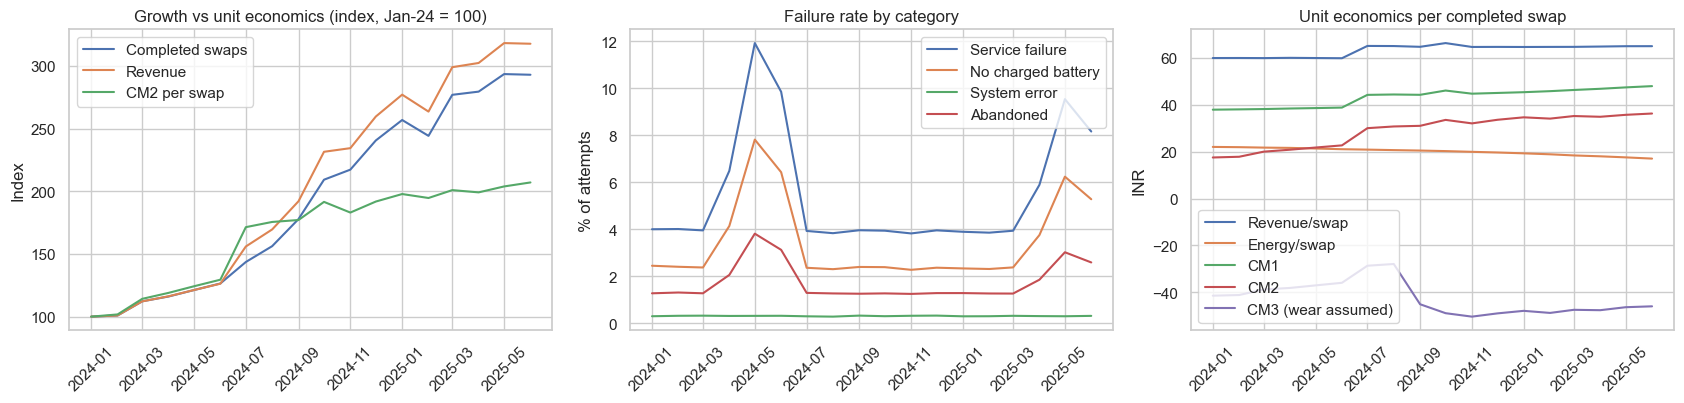

3-mo smoothed CM2/swap peaks in Jun 2025; swaps grew 2.77x (last3 vs first3); CM2/swap changed +93.1%
Service failure rate 3.98% -> 7.86%


In [ ]:
#Network performance 
M = kpi(A, "month"); display(M[["attempts","completed","revenue","completion_rate","svc_fail_rate","rev_per_swap","energy_per_swap","cm1_per_swap","cm2_per_swap","cm3_per_swap","active_riders"]].round(3))
idx = lambda s: s / s.iloc[0] * 100
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(idx(M.completed), label="Completed swaps"); ax[0].plot(idx(M.revenue), label="Revenue")
ax[0].plot(idx(M.cm2_per_swap.where(M.cm2_per_swap > 0)), label="CM2 per swap"); ax[0].set(title="Growth vs unit economics (index, Jan-24 = 100)", ylabel="Index"); ax[0].legend()
ax[1].plot(M.svc_fail_rate*100, label="Service failure"); ax[1].plot(M.stock_rate*100, label="No charged battery")
ax[1].plot(M.sys_rate*100, label="System error"); ax[1].plot(M.aband_rate*100, label="Abandoned")
ax[1].set(title="Failure rate by category", ylabel="% of attempts"); ax[1].legend()
ax[2].plot(M.rev_per_swap, label="Revenue/swap"); ax[2].plot(M.energy_per_swap, label="Energy/swap")
ax[2].plot(M.cm1_per_swap, label="CM1"); ax[2].plot(M.cm2_per_swap, label="CM2"); ax[2].plot(M.cm3_per_swap, label="CM3 (wear assumed)")
ax[2].set(title="Unit economics per completed swap", ylabel="INR"); ax[2].legend()
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

# When did growth and profitability diverge?
cm = M.cm2_per_swap.rolling(3).mean(); peak = cm.idxmax()
EV["cm2_peak_month"] = peak
EV["swaps_growth_x"] = M.completed.iloc[-3:].mean() / M.completed.iloc[:3].mean()
EV["cm2_change_pct"] = (M.cm2_per_swap.iloc[-3:].mean() / M.cm2_per_swap.iloc[:3].mean() - 1) * 100
EV["svc_fail_first3"], EV["svc_fail_last3"] = M.svc_fail_rate.iloc[:3].mean(), M.svc_fail_rate.iloc[-3:].mean()
print(f"3-mo smoothed CM2/swap peaks in {peak:%b %Y}; swaps grew {EV['swaps_growth_x']:.2f}x (last3 vs first3); CM2/swap changed {EV['cm2_change_pct']:+.1f}%")
print(f"Service failure rate {EV['svc_fail_first3']*100:.2f}% -> {EV['svc_fail_last3']*100:.2f}%")

# By city
C = kpi(A, ["month","city"]).reset_index()
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for col, t, a in [("completed","Completed swaps",ax[0]),("svc_fail_rate","Service failure rate",ax[1]),("cm2_per_swap","CM2 per swap (INR)",ax[2])]:
    sns.lineplot(data=C, x="month", y=col, hue="city", ax=a); a.set_title(t + " by city"); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print("Last-3-month city scorecard:"); display(kpi(A[A.month >= "2025-04-01"], "city")[["completed","completion_rate","svc_fail_rate","queue_mean","rev_per_swap","cm1_per_swap","cm2_per_swap"]].round(3))

# Context: weather / festival / competitor promos vs failure (daily, city)
D = A.groupby(["city","date"], observed=True).agg(att=("completed","size"), fail=("svc_fail","sum")).reset_index().merge(cdc, on=["city","date"], how="left")
D["fail_rate"] = D.fail / D.att
print(D.groupby("heat_alert").fail_rate.mean().round(4).to_dict(), D.groupby("competitor_promo_active").fail_rate.mean().round(4).to_dict())


-- by city (check n before reading differences)


,attempts,completion_rate,stock_rate,sys_rate,aband_rate,svc_fail_rate,queue_mean,queue_p90
city,,,,,,,,
Bengaluru,763296,0.9545,0.0249,0.0030,0.0132,0.0411,242.874405,433.0
Delhi NCR,768913,0.9265,0.0441,0.0030,0.0221,0.0692,242.722397,441.0
Hyderabad,711930,0.9331,0.0397,0.0030,0.0199,0.0626,242.785400,439.0
Jaipur,487634,0.9215,0.0478,0.0028,0.0236,0.0742,243.276703,444.0
Mumbai,530299,0.9555,0.0242,0.0030,0.0129,0.0401,243.244202,434.0
Pune,552910,0.9501,0.0280,0.0030,0.0146,0.0456,243.007401,434.0



-- by vehicle_class (check n before reading differences)


,attempts,completion_rate,stock_rate,sys_rate,aband_rate,svc_fail_rate,queue_mean,queue_p90
vehicle_class,,,,,,,,
2W,3399568,0.9455,0.0312,0.0030,0.0160,0.0502,242.973404,436.0
3W,415414,0.8961,0.0642,0.0031,0.0323,0.0995,242.751907,449.0



-- by charger_gen (check n before reading differences)


,attempts,completion_rate,stock_rate,sys_rate,aband_rate,svc_fail_rate,queue_mean,queue_p90
charger_gen,,,,,,,,
Gen1,1822034,0.9277,0.0434,0.0029,0.0216,0.0680,242.917206,441.0
Gen2,1620707,0.9515,0.0269,0.0030,0.0142,0.0442,242.955399,434.0
Gen3,372241,0.9516,0.0271,0.0030,0.0139,0.0440,243.079803,434.0


... (2 outputs left out)


-- by wave (check n before reading differences)


,attempts,completion_rate,stock_rate,sys_rate,aband_rate,svc_fail_rate,queue_mean,queue_p90
wave,,,,,,,,
Launch,3068824,0.9376,0.0366,0.0030,0.0186,0.0581,242.938004,438.0
Wave1_2024H2,501098,0.9512,0.0273,0.0030,0.0142,0.0445,242.878098,434.0
Wave2_2025H1,245060,0.9501,0.0280,0.0029,0.0144,0.0454,243.235199,435.0



-- by conn (check n before reading differences)


,attempts,completion_rate,stock_rate,sys_rate,aband_rate,svc_fail_rate,queue_mean,queue_p90
conn,,,,,,,,
fair,669686,0.9370,0.0370,0.0030,0.0187,0.0587,242.832504,438.0
good,2503439,0.9417,0.0338,0.0030,0.0172,0.0540,242.938004,437.0
poor,641857,0.9374,0.0366,0.0029,0.0187,0.0582,243.114899,439.0


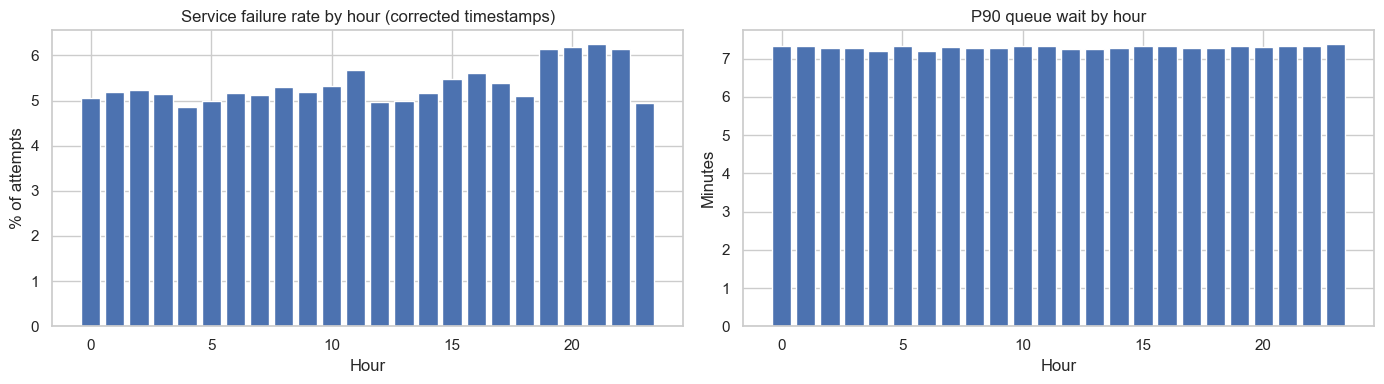

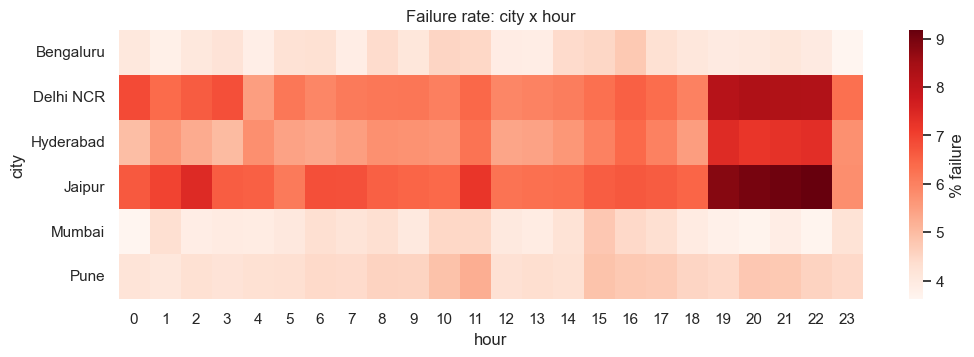

              attempts  svc_fail_rate  queue_mean
season                                           
Winter          759370         0.0391  243.154007
Summer         1339617         0.0690  242.845795
Monsoon         994321         0.0620  242.843796
Post-monsoon    721674         0.0390  243.070999
Worst 10% of stations (15): 15.2% of attempts but 22.6% of service failures


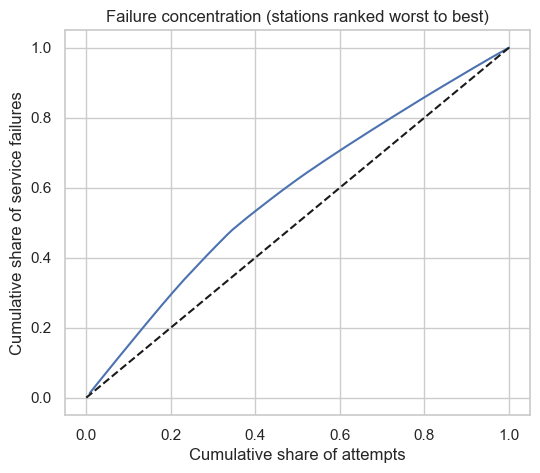

,hours,attempts,stock_fail_rate
stockout,,,
0.0,1006151.0,3711215.0,0.033902
1.0,21010.0,78133.0,0.077099


Share of 'no charged battery' failures that happen in hours with unknown telemetry: 0.007


In [ ]:
#S5. Service quality (core Q2
def cut(by, df=A):
    o = kpi(df, by); o["queue_p90"] = df.groupby(by, observed=True).queue_wait_sec.quantile(.9); return o
for by in ["city","vehicle_class","charger_gen","loc_type","wave","conn"]:
    t = cut(by)[["attempts","completion_rate","stock_rate","sys_rate","aband_rate","svc_fail_rate","queue_mean","queue_p90"]]
    print(f"\n-- by {by} (check n before reading differences)"); display(t.round(4))

H = cut("hour"); fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(H.index, H.svc_fail_rate*100); ax[0].set(title="Service failure rate by hour (corrected timestamps)", xlabel="Hour", ylabel="% of attempts")
ax[1].bar(H.index, H.queue_p90/60); ax[1].set(title="P90 queue wait by hour", xlabel="Hour", ylabel="Minutes"); plt.tight_layout(); plt.show()
hm = A.groupby(["city","hour"], observed=True).svc_fail.mean().unstack()*100
plt.figure(figsize=(12, 3.5)); sns.heatmap(hm, cmap="Reds", cbar_kws={"label": "% failure"}); plt.title("Failure rate: city x hour"); plt.show()

# Season / month
A["season"] = pd.cut(A.ts.dt.month, [0,2,5,9,12], labels=["Winter","Summer","Monsoon","Post-monsoon"])
print(cut("season")[["attempts","svc_fail_rate","queue_mean"]].round(4))

# Concentration: are failures spread evenly?
sf = stn.sort_values("fail_rate", ascending=False); sf["cum_att"] = sf.att.cumsum()/sf.att.sum(); sf["cum_fail"] = sf.fail.cumsum()/sf.fail.sum()
top10 = int(len(sf)*0.1); EV["top10pct_stations_share_of_failures"] = sf.fail.iloc[:top10].sum()/sf.fail.sum()
EV["top10pct_stations_share_of_attempts"] = sf.att.iloc[:top10].sum()/sf.att.sum()
print(f"Worst 10% of stations ({top10}): {EV['top10pct_stations_share_of_attempts']*100:.1f}% of attempts but {EV['top10pct_stations_share_of_failures']*100:.1f}% of service failures")
plt.figure(figsize=(6,5)); plt.plot(sf.cum_att, sf.cum_fail); plt.plot([0,1],[0,1],"k--")
plt.title("Failure concentration (stations ranked worst to best)"); plt.xlabel("Cumulative share of attempts"); plt.ylabel("Cumulative share of service failures"); plt.show()

# Mechanism check: do 'no charged battery' failures occur in telemetry-confirmed stockout hours?
kn = sh[sh.stockout.notna()]
r = kn.groupby("stockout").apply(lambda d: pd.Series({"hours": len(d), "attempts": d.att.sum(), "stock_fail_rate": d.fs.sum()/d.att.sum()}))
display(r); EV["stock_fail_rate_in_stockout_hr"] = r.loc[1.0, "stock_fail_rate"] if 1.0 in r.index else np.nan
EV["stock_fail_rate_normal_hr"] = r.loc[0.0, "stock_fail_rate"] if 0.0 in r.index else np.nan
print("Share of 'no charged battery' failures that happen in hours with unknown telemetry:",
      round(sh[sh.stockout.isna()].fs.sum()/sh.fs.sum(), 3))

hourly columns: ['station_id', 'hour_start', 'charged_2w_avg', 'charged_2w_min', 'charged_3w_min', 'packs_charging', 'packs_quarantined', 'chargers_online', 'ambient_temp_c', 'cabinet_temp_c', 'avg_charge_minutes', 'outage_minutes', 'grid_kwh', 'telemetry_status', 'city', 'slots_3w', 'stockout', 'cab_hot']
mapped -> {'outage': 'outage_minutes', 'charge_time': 'avg_charge_minutes', 'chargers_online': 'chargers_online'}
Station scorecard n = 150 | stations with no attempts: 0


,station_id,city,charger_generation,location_type,expansion_wave,att,util,fail_rate,q_p90,stockout_rate,outage_min,cm2_per_swap
36,STN-DEL-037,Delhi NCR,Gen1,commercial_hub,Launch,30838,3.204,0.087,445.0,0.026,360,31.080
47,STN-DEL-048,Delhi NCR,Gen1,market,Launch,34646,3.603,0.085,450.0,0.024,240,30.916
141,STN-JAI-142,Jaipur,Gen1,commercial_hub,Launch,33319,3.088,0.083,446.0,0.052,60,30.023
140,STN-JAI-141,Jaipur,Gen1,commercial_hub,Launch,45594,4.755,0.083,450.0,0.029,240,33.368
136,STN-JAI-137,Jaipur,Gen1,commercial_hub,Launch,44371,9.253,0.083,444.0,0.071,240,34.105
44,STN-DEL-045,Delhi NCR,Gen1,commercial_hub,Launch,32237,3.362,0.083,444.0,0.025,60,25.954
135,STN-JAI-136,Jaipur,Gen1,transit_hub,Launch,29340,3.498,0.082,441.0,0.078,180,25.232
137,STN-JAI-138,Jaipur,Gen1,market,Launch,48945,6.810,0.082,446.0,0.039,60,34.691
39,STN-DEL-040,Delhi NCR,Gen1,market,Launch,40335,3.062,0.082,442.0,0.042,120,30.295
42,STN-DEL-043,Delhi NCR,Gen1,commercial_hub,Launch,49597,6.905,0.082,444.0,0.034,240,34.019


{'Mid': 62, 'Low utilisation': 38, 'High-demand healthy': 27, 'High-demand underperformer': 23}


,n,att,fail,q90,stockout,cm2_per_swap
segment,,,,,,
High-demand healthy,27,648834,0.042,432.996,0.006,34.592
High-demand underperformer,23,713020,0.060,438.696,0.023,34.731
Low utilisation,38,780659,0.050,436.647,0.009,28.046
Mid,62,1672469,0.055,437.194,0.015,30.137


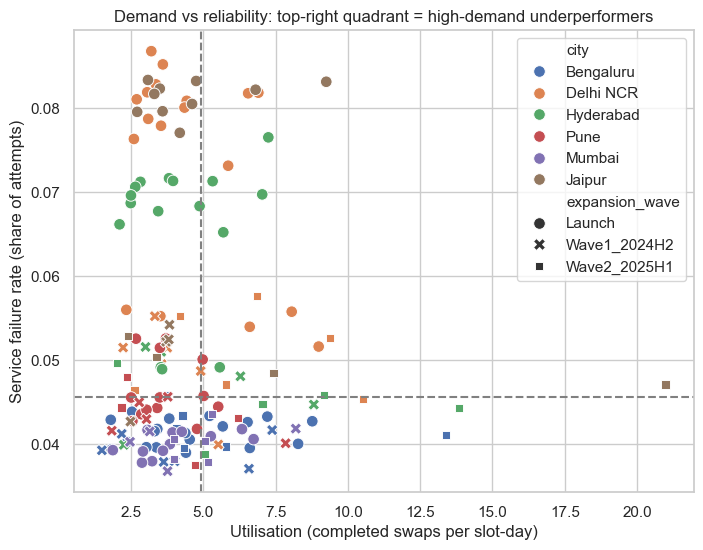


-- cohort: charger_generation


,stations,util,fail,q90,stockout,charge_min,tickets_1k,cm2_swap
charger_generation,,,,,,,,
Gen1,51,4.165,0.067,440.827,0.033,91.813,12.326,30.059
Gen2,62,4.256,0.044,434.315,0.004,64.254,10.107,30.116
Gen3,37,5.858,0.044,434.319,0.003,42.153,12.389,34.238



-- cohort: location_type


,stations,util,fail,q90,stockout,charge_min,tickets_1k,cm2_swap
location_type,,,,,,,,
commercial_hub,44,5.232,0.056,437.625,0.017,76.637,11.243,31.190
highway_fuel_pump,21,4.871,0.046,435.138,0.004,57.020,12.110,30.618
market,47,4.651,0.054,437.251,0.015,68.361,11.496,33.060
residential,21,4.049,0.048,434.357,0.008,62.032,11.247,29.970
tech_park,7,3.706,0.048,435.429,0.016,72.189,10.132,31.854
transit_hub,10,3.095,0.052,436.580,0.016,63.542,11.730,24.551



-- cohort: expansion_wave


,stations,util,fail,q90,stockout,charge_min,tickets_1k,cm2_swap
expansion_wave,,,,,,,,
Launch,90,4.273,0.057,437.963,0.020,79.844,10.940,29.900
Wave1_2024H2,30,4.106,0.045,434.270,0.004,59.161,11.591,31.179
Wave2_2025H1,30,6.177,0.045,434.490,0.003,42.168,12.713,34.688


... (7 outputs left out)

,attempt_share
city,
Bengaluru,0.200
Delhi NCR,0.202
Hyderabad,0.187
Jaipur,0.128
Mumbai,0.139
Pune,0.145



Launch-wave stations only, monthly trend (same stations, so no composition change):


,fail,q90
month,,
2024-01-01,0.0400,433.0
2024-02-01,0.0401,436.0
2024-03-01,0.0395,432.0
2024-04-01,0.0648,440.0
2024-05-01,0.1193,455.0
2024-06-01,0.0985,448.0
2024-07-01,0.0392,434.0
2024-08-01,0.0383,433.0
2024-09-01,0.0395,433.0


Decommissioned stations: 1 | with competitor nearby: 10


In [ ]:
#   STATION & GEOGRAPHIC ANALYSIS (replace the whole cell) 

def pick(df, *hints):
    cols = {c.lower(): c for c in df.columns}
    for h in hints:
        if h in cols: return cols[h]                    # exact match first
    for h in hints:
        for lc, c in cols.items():
            if h in lc: return c                        # then substring match
    return None

print("hourly columns:", list(hr.columns))
c_out  = pick(hr, "outage_minutes", "outage")
c_chg  = pick(hr, "avg_charge_minutes", "avg_charge_min", "charge_minutes", "charge_min", "charge_dur")
c_onl  = pick(hr, "chargers_online", "online")
print("mapped ->", dict(outage=c_out, charge_time=c_chg, chargers_online=c_onl))

# --- 1) demand and service by station (attempt-level, from analysis set A) ---
D_ = A.groupby("station_id", observed=True).agg(
        att=("completed", "size"), done=("completed", "sum"), svc_fail=("svc_fail", "sum"),
        stock=("f_stock", "sum"), rev=("rev", "sum"), en=("energy_cost", "sum"),
        first=("ts", "min"), last=("ts", "max")).reset_index()
D_["station_id"] = D_["station_id"].astype(str)
D_["q_p90"] = D_["station_id"].map(A.groupby("station_id", observed=True).queue_wait_sec.quantile(.9).rename(lambda i: str(i)))

# --- 2) hourly telemetry by station (only hours with a known stock reading for stockout) ---
hk = hr[hr.stockout.notna()]
agg = {"stockout_rate": ("stockout", "mean")}
if c_out: agg["outage_min"]      = (c_out, "sum")
if c_chg: agg["avg_charge_min"]  = (c_chg, "mean")
if c_onl: agg["chargers_online"] = (c_onl, "mean")
hs = hk.groupby("station_id").agg(**agg).reset_index()
for c in ["outage_min", "avg_charge_min", "chargers_online"]:
    if c not in hs.columns: hs[c] = np.nan             # keep downstream column names stable
hs_all = (hr.groupby("station_id").telemetry_status.apply(lambda s: (s != "ok").mean())
            .rename("telemetry_gap").reset_index())

# --- 3) tickets by station (duplicates excluded; blank station_id ignored) ---
tkn = (tk[(tk.resolution_status != "duplicate") & tk.station_id.notna()]
         .groupby("station_id").size().rename("tickets").reset_index())

# --- 4) station scorecard (one row per station; all joins are many-to-one on station_id) ---
base = st[~st.station_id.astype(str).str.startswith("STN-TST")].copy()
base["station_id"] = base.station_id.astype(str)
for d_ in (hs, hs_all, tkn):
    d_["station_id"] = d_["station_id"].astype(str)
SC = (base.merge(D_, on="station_id", how="left")
          .merge(hs, on="station_id", how="left")
          .merge(hs_all, on="station_id", how="left")
          .merge(tkn, on="station_id", how="left"))
assert SC.station_id.is_unique, "join fan-out: station_id duplicated"

SC["days_live"] = ((SC["last"] - SC["first"]).dt.days + 1).clip(lower=1)
SC["slots"]     = SC.slots_2w + SC.slots_3w
SC["util"]      = SC.done / (SC.slots * SC.days_live)            # completed swaps per slot-day
SC["fail_rate"] = SC.svc_fail / SC.att
SC["fixed_total"]   = (SC.monthly_rent_inr + SC.monthly_maintenance_inr) * SC.days_live / 30.4
SC["cm2_station"]   = SC.rev - SC.en - SC.fixed_total
SC["cm2_per_swap"]  = SC.cm2_station / SC.done.replace(0, np.nan)
SC["tickets_per_1k"] = SC.tickets.fillna(0) / SC.done.replace(0, np.nan) * 1000

print("Station scorecard n =", len(SC), "| stations with no attempts:", int(SC.att.isna().sum()))
show = ["station_id", "city", "charger_generation", "location_type", "expansion_wave", "att", "util",
        "fail_rate", "q_p90", "stockout_rate", "outage_min", "cm2_per_swap"]
display(SC[show].sort_values("fail_rate", ascending=False).head(15).round(3))

# --- 5) segmentation: demand vs reliability ---
hi_d, hi_f, lo_u = SC.util.quantile(.67), SC.fail_rate.median(), SC.util.quantile(.25)
SC["segment"] = np.select(
    [(SC.util >= hi_d) & (SC.fail_rate > hi_f), (SC.util >= hi_d), SC.util <= lo_u],
    ["High-demand underperformer", "High-demand healthy", "Low utilisation"], "Mid")
print(SC.segment.value_counts().to_dict())
EV["n_high_demand_underperformers"] = int((SC.segment == "High-demand underperformer").sum())
display(SC.groupby("segment").agg(n=("station_id", "size"), att=("att", "sum"), fail=("fail_rate", "mean"),
        q90=("q_p90", "mean"), stockout=("stockout_rate", "mean"), cm2_per_swap=("cm2_per_swap", "mean")).round(3))

plt.figure(figsize=(8, 6))
sns.scatterplot(data=SC, x="util", y="fail_rate", hue="city", style="expansion_wave", s=70)
plt.axvline(hi_d, ls="--", c="grey"); plt.axhline(hi_f, ls="--", c="grey")
plt.title("Demand vs reliability: top-right quadrant = high-demand underperformers")
plt.xlabel("Utilisation (completed swaps per slot-day)"); plt.ylabel("Service failure rate (share of attempts)")
plt.show()

# --- 6) cohorts (check 'stations' count before reading any difference) ---
for by in ["charger_generation", "location_type", "expansion_wave", "connectivity_tier", "host_type"]:
    print(f"\n-- cohort: {by}")
    display(SC.groupby(by).agg(stations=("station_id", "size"), util=("util", "mean"), fail=("fail_rate", "mean"),
            q90=("q_p90", "mean"), stockout=("stockout_rate", "mean"), charge_min=("avg_charge_min", "mean"),
            tickets_1k=("tickets_per_1k", "mean"), cm2_swap=("cm2_per_swap", "mean")).round(3))

# --- 7) expansion waves: placement vs demand ---
print("\nShare of each wave's stations located in each city (columns sum to 1):")
w1 = SC.groupby(["city", "expansion_wave"]).size().unstack(fill_value=0)
display(w1.div(w1.sum(), axis=1).round(2))
print("Share of attempts by city (demand):")
display((SC.groupby("city").att.sum() / SC.att.sum()).round(3).to_frame("attempt_share"))

print("\nLaunch-wave stations only, monthly trend (same stations, so no composition change):")
Lq = A.loc[A.wave.astype(str) == "Launch"]
L = Lq.groupby("month", observed=True).agg(fail=("svc_fail", "mean"))
L["q90"] = Lq.groupby("month", observed=True).queue_wait_sec.quantile(.9)
display(L.round(4))

print("Decommissioned stations:", int(st.decommissioned_date.notna().sum()),
      "| with competitor nearby:", int(st.competitor_within_1_5km_since.notna().sum()))

,packs,cycles,age,soh_now,loss,loss_100,cost
supplier,,,,,,,
Amptek,1307,600.58,252.25,81.01,18.19,3.03,37724.12
Cellora,3555,604.46,441.17,80.93,18.25,3.02,37245.41
Kyron,1638,398.57,229.71,63.75,35.46,9.48,37532.74


Kruskal-Wallis supplier loss/100 cycles: H=3408.9 p=0.00e+00


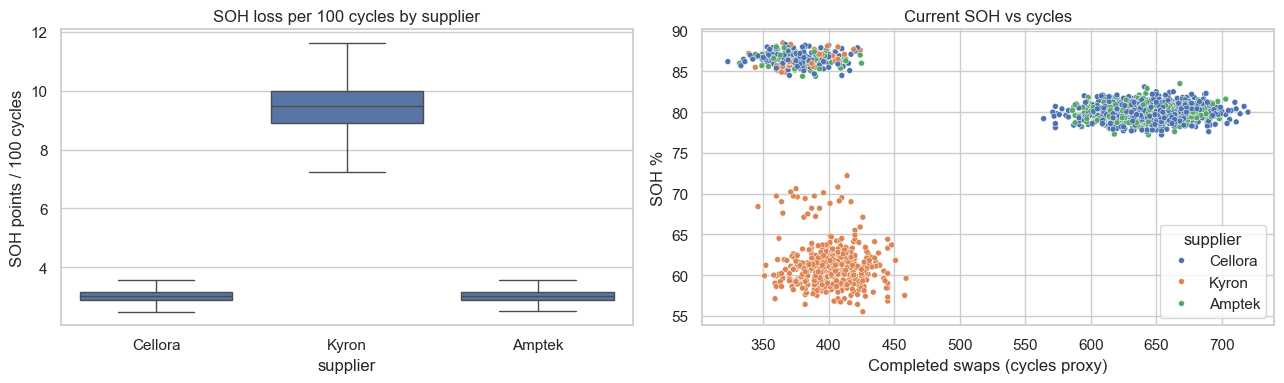

Outlier lots (|z|>2, n>=25):


,supplier,manufacturing_lot,n,loss_100,soh_now,z
41,Cellora,CE-2504,135,3.06,80.92,2.08


km coverage: 105.2% of completed swaps


,size,mean
soh_bin,,
"(0.0, 80.0]",425028,0.740
"(80.0, 85.0]",695647,0.916
"(85.0, 90.0]",915823,0.982
"(90.0, 95.0]",960634,1.071
"(95.0, 100.1]",774705,1.143


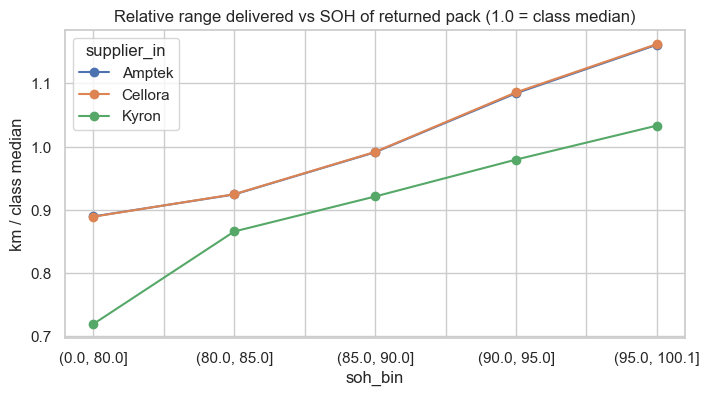

Spearman SOH vs relative range: 0.645
             attempts  svc_fail_rate  sys_rate  queue_mean
supplier_in                                               
Amptek         785730         0.0519       0.0  244.522797
Cellora       2146016         0.0511       0.0  244.339203
Kyron          855378         0.0586       0.0  244.479202
         quarantine  charge_min  stockout
cab_hot                                  
False          0.00      73.165     0.005
True           0.01      91.567     0.125


In [ ]:
#Battery and equipment (core Q4)
cyc_out = A[A.completed].battery_out_id.value_counts(); cyc_in = A.battery_in_id.value_counts()
bat["cycles"] = bat.battery_id.map(cyc_out).fillna(0)
end = bat.retired_date.fillna(pd.Timestamp("2025-06-30")); bat["age_days"] = (end - bat.commission_date).dt.days
bat["soh_loss"] = bat.initial_soh_pct - bat.current_soh_pct
bat["loss_per_100cyc"] = bat.soh_loss / (bat.cycles/100).replace(0, np.nan)
bb = bat[bat.cycles >= 50]
sup = bb.groupby("supplier").agg(packs=("battery_id","size"), cycles=("cycles","mean"), age=("age_days","mean"), soh_now=("current_soh_pct","mean"),
        loss=("soh_loss","mean"), loss_100=("loss_per_100cyc","median"), cost=("purchase_cost_inr","mean")); display(sup.round(2))
groups = [g_.loss_per_100cyc.dropna() for _, g_ in bb.groupby("supplier")]
print("Kruskal-Wallis supplier loss/100 cycles: H=%.1f p=%.2e" % stats.kruskal(*groups))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=bb, x="supplier", y="loss_per_100cyc", ax=ax[0], showfliers=False); ax[0].set(title="SOH loss per 100 cycles by supplier", ylabel="SOH points / 100 cycles")
sns.scatterplot(data=bb.sample(min(2000,len(bb)), random_state=1), x="cycles", y="current_soh_pct", hue="supplier", s=18, ax=ax[1]); ax[1].set(title="Current SOH vs cycles", xlabel="Completed swaps (cycles proxy)", ylabel="SOH %")
plt.tight_layout(); plt.show()

# Lot cohorts: flag lots whose degradation is a z-outlier within supplier, n>=25
lot = bb.groupby(["supplier","manufacturing_lot"]).agg(n=("battery_id","size"), loss_100=("loss_per_100cyc","median"), soh_now=("current_soh_pct","mean")).reset_index()
lot = lot[lot.n >= 25]; lot["z"] = lot.groupby("supplier").loss_100.transform(lambda s: (s - s.mean())/s.std())
print("Outlier lots (|z|>2, n>=25):"); display(lot[lot.z.abs() > 2].sort_values("z", ascending=False).round(2)); EV["n_outlier_lots"] = int((lot.z.abs()>2).sum())
bat_outlier_lots = set(lot[lot.z > 2].manufacturing_lot)

# Delivered range: km on RETURNED pack vs its SOH, normalised by class median (valid km only)
R = A.loc[A.km_clean.notna() & A.soh_in_pct_clean.notna(), ["km_clean","soh_in_pct_clean","vehicle_class","supplier_in","lot_in","charger_gen"]].copy()
R["km_rel"] = R.km_clean / R.groupby("vehicle_class", observed=True).km_clean.transform("median")
R["soh_bin"] = pd.cut(R.soh_in_pct_clean, [0,80,85,90,95,100.1])
print(f"km coverage: {len(R)/A.completed.sum()*100:.1f}% of completed swaps")
tb = R.groupby("soh_bin", observed=True).km_rel.agg(["size","mean"]); display(tb.round(3))
sns.lineplot(data=R.sample(min(300000,len(R)),random_state=1), x="soh_bin", y="km_rel", hue="supplier_in", estimator="mean", errorbar=None) if False else None
pv = R.groupby(["supplier_in","soh_bin"], observed=True).km_rel.mean().unstack(0); pv.plot(marker="o", figsize=(8,4), title="Relative range delivered vs SOH of returned pack (1.0 = class median)"); plt.ylabel("km / class median"); plt.show()
print("Spearman SOH vs relative range:", stats.spearmanr(R.soh_in_pct_clean, R.km_rel)[0].round(3))
# Supplier vs failure (association only)
print(cut("supplier_in")[["attempts","svc_fail_rate","sys_rate","queue_mean"]].round(4))
# Temperature link
hr["cab_hot"] = hr.cabinet_temp_c > hr.cabinet_temp_c.quantile(.9)
print(hr.groupby("cab_hot").agg(quarantine=("packs_quarantined","mean"), charge_min=("avg_charge_minutes","mean"), stockout=("stockout","mean")).round(3))

In [ ]:
#. Pricing and partner economics (core Q5)
# 8.1 Base price change: detect from data instead of assuming a date
lp = A[A.tariff_code.astype(str) == "STD"].groupby(["month","vehicle_class"], observed=True).list_price_inr.median().unstack(); display(lp)
chg_month = lp.diff().abs().sum(axis=1).idxmax(); EV["base_price_change_month"] = chg_month; print("Largest list-price step:", chg_month)
tc = A.groupby(["month","tariff_code"], observed=True).size().unstack(fill_value=0); display(tc.div(tc.sum(axis=1), axis=0).round(3))

# 8.2 Interrupted time series around the base price change (no untreated control -> weaker causal claim)
wk = A[A.completed].groupby(pd.Grouper(key="date", freq="W")).agg(swaps=("completed","size"), riders=("rider_id","nunique"), rev=("rev","sum"), en=("energy_cost","sum"))
wk["swaps_per_rider"] = wk.swaps/wk.riders; wk["cm1"] = (wk.rev-wk.en)/wk.swaps; wk["t"] = np.arange(len(wk)); wk["post"] = (wk.index >= chg_month).astype(int); wk["t_post"] = wk.t*wk.post
for y in ["swaps_per_rider","cm1"]:
    m = smf.ols(f"{y} ~ t + post + t_post", wk).fit(cov_type="HAC", cov_kwds={"maxlags":4})
    print(f"ITS {y}: level shift={m.params['post']:.3f} (p={m.pvalues['post']:.3f}), slope change={m.params['t_post']:.4f} (p={m.pvalues['t_post']:.3f})")

# 8.3 Peak/off-peak pilot: detect pilot cities, start date and peak hours from data
pk = A[A.tariff_code.astype(str).isin(["PEAK","OFFPEAK"])]
pilot_cities = list(pk.city.dropna().unique()); pilot_start = pk.date.min()
peak_hours = sorted(pk.loc[pk.tariff_code.astype(str)=="PEAK","hour"].value_counts().loc[lambda s: s > s.max()*0.2].index)
print("Pilot cities:", pilot_cities, "| start:", pilot_start.date(), "| peak hours:", peak_hours); EV["pilot_cities"] = pilot_cities
# exposed segment = independents billed per swap; contrast = partner-billed where surcharge not billable
fp["surch"] = fp.peak_surcharge_billable.eq("Y"); A["surch_partner"] = pd.Categorical(lk(fp.set_index("partner_id").surch.astype(float), A.partner)) if False else lk(fp.set_index("partner_id").surch.astype(float), A.partner)
def panel(mask):
    d = A[A.completed & mask]; d = d.assign(week=d.date.dt.to_period("W").dt.start_time, peak=d.hour.isin(peak_hours))
    p_ = d.groupby(["city","week"], observed=True).agg(swaps=("completed","size"), peak_share=("peak","mean"), rev=("rev","mean"), en=("energy_cost","mean")).reset_index()
    p_["cm1"] = p_.rev - p_.en; p_["treated"] = p_.city.astype(str).isin(pilot_cities).astype(int); p_["post"] = (p_.week >= pilot_start).astype(int); p_["tp"] = p_.treated*p_.post
    p_["lswaps"] = np.log(p_.swaps); return p_
pan_ind = panel(A.partner.isna())
pan_ex  = panel(A.surch_partner == 0.0)          # partners that do NOT pay surcharge (contrast group)
pan_py  = panel(A.surch_partner == 1.0)
for name, pp in [("Independents (exposed)", pan_ind), ("Partners surcharge=N (not exposed)", pan_ex), ("Partners surcharge=Y", pan_py)]:
    if len(pp) < 30: print(name, ": too little data"); continue
    for y in ["peak_share","lswaps","rev","cm1"]:
        m = smf.ols(f"{y} ~ tp + C(city) + C(week)", pp).fit(cov_type="HC1")
        print(f"DiD [{name}] {y:10s}: effect={m.params['tp']:+.4f}  95%CI=({m.conf_int().loc['tp',0]:+.4f},{m.conf_int().loc['tp',1]:+.4f}) p={m.pvalues['tp']:.3f}")
# parallel-trends visual
fig, ax = plt.subplots(figsize=(10,4)); sns.lineplot(data=pan_ind, x="week", y="peak_share", hue="treated"); ax.axvline(pilot_start, c="k", ls="--")
ax.set(title="Peak-hour share of swaps (independents): pilot (1) vs non-pilot (0) cities", ylabel="Share in peak hours"); plt.show()

# 8.4 Partner economics (CM per swap, not revenue rank)
P = A[A.partner.notna()].groupby("partner", observed=True).agg(swaps=("completed","sum"), riders=("rider_id","nunique"), revenue=("rev","sum"),
      list_p=("list_c","sum"), disc=("disc_c","sum"), energy=("energy_cost","sum"), fixed=("fixed_alloc","sum"), wear=("wear","sum")).reset_index()
P["eff_discount_%"] = P.disc/P.list_p*100; P["rev_swap"] = P.revenue/P.swaps
P["cm1_swap"] = (P.revenue-P.energy)/P.swaps; P["cm2_swap"] = (P.revenue-P.energy-P.fixed)/P.swaps; P["cm3_swap"] = (P.revenue-P.energy-P.fixed-P.wear)/P.swaps
P["total_cm2"] = P.revenue-P.energy-P.fixed
P = P.merge(fp[["partner_id","partner_name","partner_segment","contract_type","discount_pct","amendment_date","discount_pct_after_amendment","peak_surcharge_billable","payment_terms_days"]], left_on="partner", right_on="partner_id")
ind = A[A.partner.isna() & A.completed]; ind_cm1 = (ind.rev.sum()-ind.energy_cost.sum())/len(ind); ind_cm2 = (ind.rev.sum()-ind.energy_cost.sum()-ind.fixed_alloc.sum())/len(ind)
P["rank_revenue"] = P.revenue.rank(ascending=False); P["rank_cm2_swap"] = P.cm2_swap.rank(ascending=False)
display(P[["partner_name","partner_segment","contract_type","swaps","revenue","eff_discount_%","cm1_swap","cm2_swap","cm3_swap","total_cm2","rank_revenue","rank_cm2_swap","payment_terms_days"]].sort_values("revenue", ascending=False).round(2))
print(f"Independent riders: CM1/swap={ind_cm1:.2f}, CM2/swap={ind_cm2:.2f}")
big = P.sort_values("revenue", ascending=False).iloc[0]; EV["largest_partner"] = big.partner_name; EV["largest_partner_cm2_swap"] = big.cm2_swap; EV["largest_partner_rank_cm2"] = big.rank_cm2_swap
EV["partner_share_swaps"] = P.swaps.sum()/A.completed.sum(); EV["independent_cm2_swap"] = ind_cm2
plt.figure(figsize=(9,5)); sns.scatterplot(data=P, x="revenue", y="cm2_swap", size="swaps", hue="partner_segment", sizes=(60,500))
for _, r_ in P.iterrows(): plt.annotate(r_.partner_name, (r_.revenue, r_.cm2_swap), fontsize=8)
plt.axhline(ind_cm2, ls="--", c="grey"); plt.title("Partner value: revenue vs CM2 per swap (dashed = independents)"); plt.xlabel("Revenue (INR)"); plt.ylabel("CM2 per swap (INR)"); plt.show()

# Contract amendment before/after, with independents as the same-window comparison
rows = []
for _, p_ in fp[fp.amendment_date.notna()].iterrows():
    for lbl, m_ in [("pre", A.date < p_.amendment_date), ("post", A.date >= p_.amendment_date)]:
        for who, mm in [("partner", A.partner.astype(str) == p_.partner_id), ("independent", A.partner.isna())]:
            d = A[A.completed & m_ & mm]; 
            if len(d) == 0: continue
            rows.append(dict(partner=p_.partner_name, period=lbl, group=who, swaps=len(d), rev_swap=d.rev.mean(), cm1_swap=(d.rev.sum()-d.energy_cost.sum())/len(d)))
amd = pd.DataFrame(rows); display(amd.pivot_table(index=["partner","group"], columns="period", values=["swaps","rev_swap","cm1_swap"]).round(2))

vehicle_class,2W,3W
month,,
2024-01-01,60.0,100.0
2024-02-01,60.0,100.0
2024-03-01,60.0,100.0
2024-04-01,60.0,100.0
2024-05-01,60.0,100.0
2024-06-01,60.0,100.0
2024-07-01,65.0,110.0
2024-08-01,65.0,110.0
2024-09-01,65.0,110.0


Largest list-price step: 2024-07-01 00:00:00


tariff_code,PARTNER,STD,OFFPEAK,PEAK
month,,,,
2024-01-01,0.673,0.327,0.000,0.000
2024-02-01,0.672,0.328,0.000,0.000
2024-03-01,0.668,0.332,0.000,0.000
2024-04-01,0.662,0.338,0.000,0.000
2024-05-01,0.661,0.339,0.000,0.000
2024-06-01,0.657,0.343,0.000,0.000
2024-07-01,0.655,0.345,0.000,0.000
2024-08-01,0.657,0.343,0.000,0.000
2024-09-01,0.658,0.342,0.000,0.000


ITS swaps_per_rider: level shift=0.378 (p=0.535), slope change=0.0146 (p=0.265)
ITS cm1: level shift=4.081 (p=0.000), slope change=0.0321 (p=0.000)
Pilot cities: ['Bengaluru', 'Pune'] | start: 2024-10-01 | peak hours: [12, 13, 19, 20, 21]


PatsyError: Error evaluating factor: TypeError: 'DataFrame' object is not callable
    peak_share ~ tp + C(city) + C(week)
                                ^^^^^^^

In [ ]:
#Rider retention and churn
# Definitions: new rider = signup_date >= 2024-01-01. Activation = >=1 completed swap in days 0-13 after signup.
# Retained = >=1 completed swap in days 14-43. Observable only if signup <= 2025-05-17 (44 days of follow-up).
# Features come ONLY from days 0-13 (exposure window) -> outcome window is later, so no leakage.
new = riders[riders.signup_date >= "2024-01-01"].copy(); new_ids = set(new.rider_id)
sig = lk(rx.signup_date, A.rider_id).astype("datetime64[D]")
A["d"] = (A.ts.values.astype("datetime64[D]") - sig).astype("timedelta64[D]").astype("int32")
E = A[A.d.between(0, 13) & A.rider_id.isin(new_ids)].sort_values("ts")
first = E.groupby("rider_id", observed=True).first()
f = E.groupby("rider_id", observed=True).agg(att=("completed","size"), comp=("completed","sum"), n_stock=("f_stock","sum"), n_sys=("f_sys","sum"),
        n_aband=("f_aband","sum"), q_mean=("queue_wait_sec","mean"), stn_rel=("stn_fail_rate","mean"), soh_out=("soh_out_pct_clean","mean"), price=("rev","mean"))
f["n_fail"] = f.att - f.comp; f["first_failed"] = (~first.completed).astype(int)
f["first_outcome"] = first.event_type.astype(str)
O = set(A.loc[A.d.between(14, 43) & A.completed & A.rider_id.isin(new_ids), "rider_id"].astype(str))
f.index = f.index.astype(str); f["retained"] = f.index.isin(O); f["churn"] = (~f.retained).astype(int)
f = f.join(new.set_index("rider_id")[["signup_date","signup_channel","plan_type","partner_id","vehicle_class","home_city"]])
f["fleet"] = np.where(f.partner_id.notna(), "fleet", "independent")
tkw = tk[tk.created_ts.notna()].merge(riders[["rider_id","signup_date"]], on="rider_id"); tkw = tkw[((tkw.created_ts - tkw.signup_date).dt.days).between(0, 13)]
f["tickets14"] = f.index.map(tkw[tkw.resolution_status != "duplicate"].groupby("rider_id").size()).fillna(0)
obs = f[f.signup_date <= "2025-05-17"]

# Funnel and activation
n_new = len(new[new.signup_date <= "2025-05-17"]); act = obs[obs.comp > 0]
print(f"New riders (observable): {n_new:,} | activated in 14d: {len(act):,} ({len(act)/n_new*100:.1f}%) | retained among activated: {act.retained.mean()*100:.1f}%")
EV["activation_rate"] = len(act)/n_new; EV["retention_activated"] = act.retained.mean()
# Cohort retention heatmap (monthly signup cohort x months since signup with a completed swap)
ev = A[A.completed & A.rider_id.isin(new_ids)][["rider_id","month"]].drop_duplicates(); ev["rider_id"] = ev.rider_id.astype(str)
ev = ev.merge(new[["rider_id","signup_date"]], on="rider_id"); ev["coh"] = ev.signup_date.dt.to_period("M").dt.to_timestamp()
ev["k"] = ((ev.month.dt.year - ev.coh.dt.year)*12 + ev.month.dt.month - ev.coh.dt.month)
cs = new.groupby(new.signup_date.dt.to_period("M").dt.to_timestamp()).size()
ch = ev.groupby(["coh","k"]).rider_id.nunique().unstack().div(cs, axis=0)
plt.figure(figsize=(12,6)); sns.heatmap(ch.iloc[:, :9]*100, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label":"% of cohort active"}); plt.title("Cohort retention: share of signup cohort with a completed swap, by months since signup"); plt.xlabel("Months since signup"); plt.ylabel("Signup cohort"); plt.show()

# Univariate churn by driver (Wilson CI, chi-square, n shown). Among ACTIVATED riders.
def churn_by(col, d=act):
    t = d.groupby(col, observed=True).churn.agg(n="size", churn="mean"); lo, hi = proportion_confint((t.churn*t.n).round(), t.n, method="wilson")
    t["ci_lo"], t["ci_hi"] = lo, hi; ct = pd.crosstab(d[col], d.churn); p_ = stats.chi2_contingency(ct)[1]
    t["p_chi2"] = p_; return t.round(3)
act = act.copy()
act["fail_cat"]  = pd.cut(act.n_fail, [-1,0,1,100], labels=["0 failed","1 failed","2+ failed"])
act["queue_t"]   = pd.qcut(act.q_mean, 3, labels=["low queue","mid","high queue"])
act["stnrel_t"]  = pd.qcut(act.stn_rel, 3, labels=["reliable stn","mid","unreliable stn"])
act["soh_t"]     = pd.qcut(act.soh_out, 3, labels=["low SOH out","mid","high SOH out"], duplicates="drop")
act["price_t"]   = pd.qcut(act.price, 3, labels=["low price","mid","high price"], duplicates="drop")
act["tick_cat"]  = pd.cut(act.tickets14, [-1,0,100], labels=["no ticket","ticket"])
for c in ["first_failed","fail_cat","queue_t","stnrel_t","soh_t","price_t","tick_cat","signup_channel","fleet","plan_type","vehicle_class","home_city"]:
    print(f"\n-- churn by {c}"); display(churn_by(c))

# Multivariable logistic regression (association only). z-scored numerics, categorical controls.
z = lambda s: (s - s.mean())/s.std()
X = act.assign(z_queue=z(act.q_mean), z_stn=z(act.stn_rel), z_soh=z(act.soh_out), z_price=z(act.price), n_fail_c=act.n_fail.clip(upper=3), tick=(act.tickets14 > 0).astype(int))
terms = {"first_failed":"first_failed","n_fail":"n_fail_c","queue":"z_queue","station_reliability":"z_stn","battery_SOH":"z_soh","price":"z_price",
         "ticket":"tick","channel":"C(signup_channel)","fleet":"C(fleet)","vehicle":"C(vehicle_class)","city":"C(home_city)"}
full = smf.logit("churn ~ " + " + ".join(terms.values()), X).fit(disp=0)
OR = pd.DataFrame({"odds_ratio": np.exp(full.params), "ci_lo": np.exp(full.conf_int()[0]), "ci_hi": np.exp(full.conf_int()[1]), "p": full.pvalues}).round(3); display(OR)
imp = {}
for k, v in terms.items():       # drop-one likelihood-ratio contribution
    red = smf.logit("churn ~ " + " + ".join(t for kk, t in terms.items() if kk != k), X).fit(disp=0); imp[k] = 2*(full.llf - red.llf)
imp = pd.Series(imp).sort_values(ascending=False); display(imp.round(1).to_frame("LR chi2 (drop-one)"))
EV["top_churn_factors"] = list(imp.index[:4]); EV["logit_pseudoR2"] = full.prsquared
imp.sort_values().plot.barh(figsize=(7,4), title="Relative association with churn (drop-one LR chi-square, activated new riders)"); plt.xlabel("LR chi-square"); plt.show()
print("Never-activated new riders (no completed swap in 14d):", f"{(obs.comp==0).mean()*100:.1f}%", "| first attempt failed share among never-activated:", f"{obs[obs.comp==0].first_failed.mean()*100:.1f}%")

Primary versus secondary drivers: treat a factor as primary only if it shows a large churn gap with a confidence interval that clears the others and a drop-one LR chi-square that survives controls. Anything that fails these tests, or that is correlated with fleet or vehicle model, is secondary. The data is observational, so state it that way in the report.

In [ ]:
#S10. Support tickets
T = tk[tk.resolution_status != "duplicate"].copy(); T["month"] = T.created_ts.dt.to_period("M").dt.to_timestamp()
rate = (T.groupby("month").size() / M.completed * 1000).rename("tickets_per_1k_swaps"); print(rate.round(2).to_dict())
EV["unresolved_rate"] = (T.resolution_status == "unresolved").mean()
display(T.groupby("category").agg(n=("ticket_id","size"), unresolved=("resolution_status", lambda s: (s=="unresolved").mean()), res_h=("resolution_hours","median")).round(3).sort_values("n", ascending=False))
tk["cat_adj"] = np.where(gen & tk.kw_battery_range, "battery_range (text-adjusted)", tk.category)
print("Original vs text-adjusted battery complaints:", (tk.category.str.contains("batt", na=False)).sum(), "->", (tk.cat_adj.str.contains("batt", na=False)).sum())
sc_ = tk.merge(stx[["city","charger_generation","location_type"]], left_on="station_id", right_index=True, how="left")
display(sc_.groupby("charger_generation").size().div(SC.groupby("charger_generation").done.sum()).mul(1000).round(2).to_frame("tickets per 1k completed swaps"))

In [ ]:
#S11. Root cause synthesis and investment evidence
# 11.1 Margin bridge: first 3 months vs last 3 months (per completed swap, INR)
a_, b_ = A[A.completed & (A.month <= "2024-03-01")], A[A.completed & (A.month >= "2025-04-01")]
def per(d): return pd.Series(dict(list_price=d.list_c.mean(), discount=-d.disc_c.mean(), net_rev=d.rev.mean(), energy=-d.energy_cost.mean(), fixed=-d.fixed_alloc.mean(), wear=-d.wear.mean()))
br = pd.concat([per(a_), per(b_)], axis=1, keys=["early","late"]); br["change"] = br.late - br.early; display(br.round(2))
br["cm2_early"] = None; EV["cm2_bridge"] = br.change.round(2).to_dict()
br.change.drop(["net_rev"]).plot.bar(figsize=(8,4), color=["g" if v > 0 else "r" for v in br.change.drop(["net_rev"])]); plt.title("What moved CM per swap: late vs early (INR/swap)"); plt.ylabel("INR per completed swap"); plt.show()

# 11.2 Failure growth: mix vs within-station rate (shift-share by station)
e0 = A[A.month <= "2024-03-01"].groupby("station_id", observed=True).svc_fail.agg(["size","mean"]); e1 = A[A.month >= "2025-04-01"].groupby("station_id", observed=True).svc_fail.agg(["size","mean"])
j = e1.join(e0, lsuffix="_1", rsuffix="_0"); j["mean_0"] = j.mean_0.fillna(e0["mean"].mul(e0["size"]).sum()/e0["size"].sum()); j["w1"] = j.size_1/j.size_1.sum(); j["w0"] = (j.size_0/j.size_0.sum()).fillna(0)
mix = ((j.w1 - j.w0) * j.mean_0).sum(); within = (j.w1 * (j.mean_1 - j.mean_0)).sum()
print(f"Failure-rate change {(j.w1*j.mean_1).sum()-(j.w0*j.mean_0).sum():+.4f} = mix/new-station effect {mix:+.4f} + within-station deterioration {within:+.4f}")
EV["fail_mix_effect"], EV["fail_within_effect"] = mix, within

# 11.3 Evidence table for the four proposed investments
top_sf = SC[SC.segment == "High-demand underperformer"]
EV["stock_share_of_svc_fail"] = A.f_stock.sum()/A.svc_fail.sum(); EV["sys_share"] = A.f_sys.sum()/A.svc_fail.sum(); EV["aband_share"] = A.f_aband.sum()/A.svc_fail.sum()
EV["hd_underperf_share_attempts"] = top_sf.att.sum()/SC.att.sum()
ev_tbl = pd.DataFrame({
 "1 More stations":  [f"Top 10% worst stations = {EV['top10pct_stations_share_of_failures']*100:.0f}% of failures; {EV['n_high_demand_underperformers']} high-demand underperformers carry {EV['hd_underperf_share_attempts']*100:.0f}% of attempts",
                      "If failures are concentrated at overloaded existing sites, new sites treat the wrong problem; check Wave1/Wave2 vs Launch results in S6"],
 "2 More batteries": [f"No-charged-battery share of service failures {EV['stock_share_of_svc_fail']*100:.0f}%; stock-fail rate {EV['stock_fail_rate_in_stockout_hr']:.3f} in stockout hours vs {EV['stock_fail_rate_normal_hr']:.3f} otherwise",
                      "Supports inventory only if stockouts are concentrated by hour/station; check supplier/lot outliers first (S7) so poor packs are not bought again"],
 "3 Network-wide pricing": [f"Pilot cities {EV['pilot_cities']}; see DiD estimates in S8 for peak share, volume and CM1; base-price ITS shown in S8",
                      "Roll out only if DiD shows peak shifting without volume loss, and CM gain is not just discount mix"],
 "4 Exclusive fleet deal": [f"Largest partner {EV['largest_partner']}: CM2/swap {EV['largest_partner_cm2_swap']:.1f} vs independents {EV['independent_cm2_swap']:.1f}; rank by CM2 = {EV['largest_partner_rank_cm2']:.0f} of {len(P)}; partners = {EV['partner_share_swaps']*100:.0f}% of swaps",
                      "Do not lock in exclusivity if its CM per swap is below independents or below peers; renegotiate the discount first"]}, index=["Evidence (computed)", "Decision rule"]).T
pd.set_option("display.max_colwidth", 200); display(ev_tbl)
print("\nEV summary:"); [print(f"  {k}: {v}") for k, v in EV.items()]

For each finding: Observation -> Evidence (from EV and tables) -> Interpretation -> Action.

Priority order (confirm against your output):
1. Fix reliability at the stations that carry demand (S5 concentration + S6 quadrant) before spending on new sites. Use the failure shift-share (11.2) to see whether the problem is new stations (mix) or existing ones deteriorating (within).
2. Buy batteries only where telemetry-confirmed stockout hours explain failures (S5 mechanism table), and only after supplier/lot outliers (S7) are quarantined. A few bad lots can mimic a shortage.
3. Roll pricing out only where the DiD (S8) shows peak shift without volume loss. Do not read the base-price ITS as proof, because there is no untreated control.
4. Do not sign a long-term exclusive until the partner's CM2/swap (S8) beats independents. Renegotiate the discount tier (see amendment before/after) if it does not.
5. Fix first-swap experience: compare churn for first_failed, queue and station reliability (S9). Rank by drop-one LR chi-square.

Monitoring KPIs: completion rate, stockout hour %, p90 queue, failure rate at top-decile stations, CM2/swap by segment,
D14-D43 retention of activated new riders, first-attempt failure rate, unresolved ticket rate, supplier SOH loss per 100 cycles.

# Limitations
- Simulated, observational data: associations are not proof of cause. Retention logit shows association after controls only.
- CM excludes staffing, marketing, HQ, financing and payment-term costs (not in the data). CM3 depends on the EOL_SOH = 80% assumption.
- Timestamp fix assumes all v3.2.0 events in the window are shifted by exactly 5h30. Near-duplicate rule (180s, offline_batch only) can miss longer retries or drop a genuine repeat.
- The pilot DiD has few treated and control cities, so standard errors are fragile. A parallel-trend visual is provided but pre-trends are not proven.
- Base-price effect uses an interrupted time series without a control group.
- Ticket lexicon is hand-built (English plus Hinglish) and must be tuned against the token list printed in S2.
- Retention uses a 14-day activation window and a 14-43 day return window. Results are sensitive to these definitions, so rerun with other windows.